100%|██████████| 26.4M/26.4M [00:03<00:00, 8.55MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 133kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 2.42MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 17.4MB/s]


Epoch 1/30, Loss: 0.6256, Train Accuracy: 85.32%, Test Accuracy: 84.56%
Epoch 2/30, Loss: 0.3859, Train Accuracy: 88.04%, Test Accuracy: 86.88%
Epoch 3/30, Loss: 0.3317, Train Accuracy: 89.42%, Test Accuracy: 88.07%
Epoch 4/30, Loss: 0.3023, Train Accuracy: 89.94%, Test Accuracy: 88.35%
Epoch 5/30, Loss: 0.2812, Train Accuracy: 90.50%, Test Accuracy: 88.44%
Epoch 6/30, Loss: 0.2644, Train Accuracy: 91.21%, Test Accuracy: 88.93%
Epoch 7/30, Loss: 0.2519, Train Accuracy: 91.76%, Test Accuracy: 89.80%
Epoch 8/30, Loss: 0.2399, Train Accuracy: 92.20%, Test Accuracy: 89.73%
Epoch 9/30, Loss: 0.2316, Train Accuracy: 92.50%, Test Accuracy: 89.72%
Epoch 10/30, Loss: 0.2193, Train Accuracy: 91.39%, Test Accuracy: 88.95%
Epoch 11/30, Loss: 0.2115, Train Accuracy: 92.31%, Test Accuracy: 89.33%
Epoch 12/30, Loss: 0.2035, Train Accuracy: 93.20%, Test Accuracy: 90.30%
Epoch 13/30, Loss: 0.1954, Train Accuracy: 93.48%, Test Accuracy: 90.10%
Epoch 14/30, Loss: 0.1865, Train Accuracy: 93.61%, Test Accu

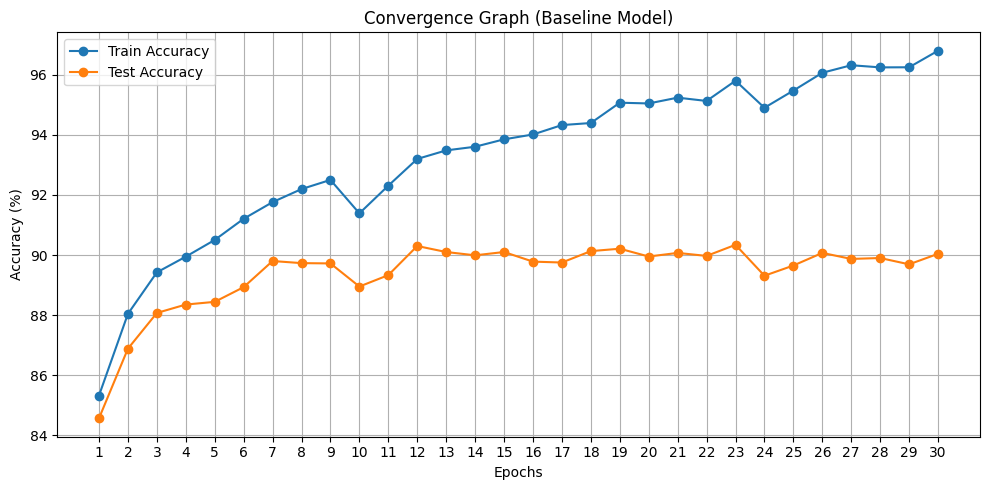

In [1]:

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

class LeNet5(nn.Module):
    def __init__(self):
        super(LeNet5, self).__init__()
        self.conv1 = nn.Conv2d(1, 6, kernel_size=5)
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.conv2 = nn.Conv2d(6, 16, kernel_size=5)
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.fc1 = nn.Linear(16 * 4 * 4, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        x = self.pool1(torch.relu(self.conv1(x)))
        x = self.pool2(torch.relu(self.conv2(x)))
        x = x.view(-1, 16 * 4 * 4)
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = self.fc3(x)
        return x

transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])
train_dataset = torchvision.datasets.FashionMNIST(root='./data', train=True, transform=transform, download=True)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_dataset = torchvision.datasets.FashionMNIST(root='./data', train=False, transform=transform, download=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

net = LeNet5()
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(net.parameters(), lr=0.001)

epoch_losses = []
train_accuracies = []
test_accuracies = []
num_epochs = 30

for epoch in range(num_epochs):
    net.train()
    running_loss = 0.0
    for i, data in enumerate(train_loader, 0):
        inputs, labels = data
        optimizer.zero_grad()
        outputs = net(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()

    epoch_loss = running_loss / len(train_loader)
    epoch_losses.append(epoch_loss)

    net.eval()

    correct_train = 0
    total_train = 0
    with torch.no_grad():
        for data in train_loader:
            inputs, labels = data
            outputs = net(inputs)
            _, predicted = torch.max(outputs.data, 1)
            total_train += labels.size(0)
            correct_train += (predicted == labels).sum().item()
    train_accuracy = 100 * correct_train / total_train
    train_accuracies.append(train_accuracy)

    correct_test = 0
    total_test = 0
    with torch.no_grad():
        for data in test_loader:
            inputs, labels = data
            outputs = net(inputs)
            _, predicted = torch.max(outputs.data, 1)
            total_test += labels.size(0)
            correct_test += (predicted == labels).sum().item()
    test_accuracy = 100 * correct_test / total_test
    test_accuracies.append(test_accuracy)

    print(f"Epoch {epoch + 1}/{num_epochs}, Loss: {epoch_loss:.4f}, Train Accuracy: {train_accuracy:.2f}%, Test Accuracy: {test_accuracy:.2f}%")

print("Finished Training")
SAVE_PATH = "baseline_model.pth"
torch.save(net.state_dict(), SAVE_PATH)
print(f"Model weights saved to {SAVE_PATH}")

plt.figure(figsize=(10, 5))
plt.plot(range(1, num_epochs + 1), train_accuracies, marker='o', label='Train Accuracy')
plt.plot(range(1, num_epochs + 1), test_accuracies, marker='o', label='Test Accuracy')
plt.title('Convergence Graph (Baseline Model)')
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True)
plt.xticks(range(1, num_epochs + 1))
plt.tight_layout()
plt.savefig("baseline_convergence_graph.png")

print(f"\nFinal Train Accuracy: {train_accuracies[-1]:.2f}%")
print(f"Final Test Accuracy: {test_accuracies[-1]:.2f}%")
print("Convergence graph saved as 'baseline_convergence_graph.png'")

Epoch 1/30, Loss: 0.8325, Train Accuracy: 79.98%, Test Accuracy: 79.23%
Epoch 2/30, Loss: 0.5693, Train Accuracy: 82.78%, Test Accuracy: 82.05%
Epoch 3/30, Loss: 0.5013, Train Accuracy: 85.53%, Test Accuracy: 84.63%
Epoch 4/30, Loss: 0.4547, Train Accuracy: 86.92%, Test Accuracy: 85.81%
Epoch 5/30, Loss: 0.4215, Train Accuracy: 87.81%, Test Accuracy: 86.75%
Epoch 6/30, Loss: 0.4044, Train Accuracy: 87.93%, Test Accuracy: 86.46%
Epoch 7/30, Loss: 0.3862, Train Accuracy: 89.11%, Test Accuracy: 87.84%
Epoch 8/30, Loss: 0.3699, Train Accuracy: 89.42%, Test Accuracy: 88.30%
Epoch 9/30, Loss: 0.3617, Train Accuracy: 89.47%, Test Accuracy: 87.82%
Epoch 10/30, Loss: 0.3535, Train Accuracy: 89.70%, Test Accuracy: 87.88%
Epoch 11/30, Loss: 0.3419, Train Accuracy: 90.12%, Test Accuracy: 88.14%
Epoch 12/30, Loss: 0.3370, Train Accuracy: 90.14%, Test Accuracy: 88.22%
Epoch 13/30, Loss: 0.3321, Train Accuracy: 90.57%, Test Accuracy: 88.89%
Epoch 14/30, Loss: 0.3261, Train Accuracy: 90.74%, Test Accu

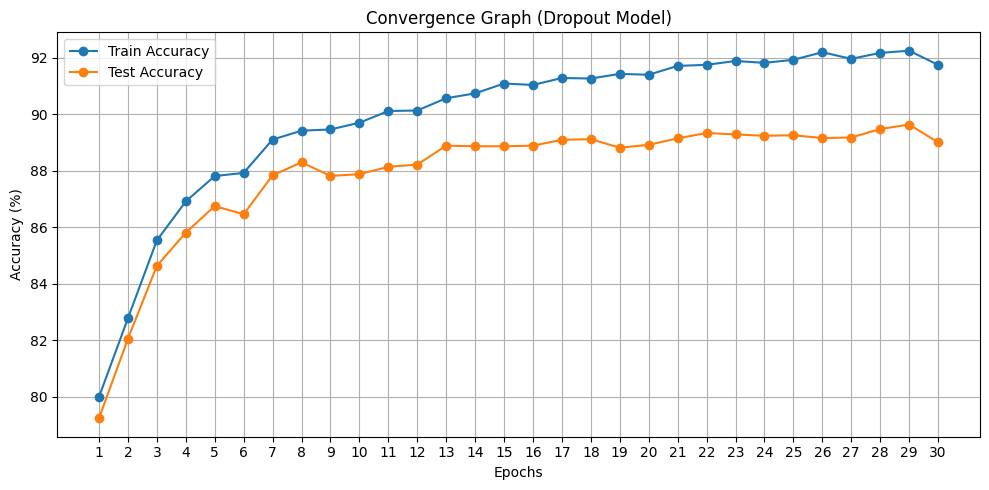

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

class LeNet5_Dropout(nn.Module):
    def __init__(self):
        super(LeNet5_Dropout, self).__init__()
        self.conv1 = nn.Conv2d(1, 6, kernel_size=5)
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.conv2 = nn.Conv2d(6, 16, kernel_size=5)
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.fc1 = nn.Linear(16 * 4 * 4, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)
        # dropout layer
        self.dropout = nn.Dropout(p=0.5)

    def forward(self, x):
        x = self.pool1(torch.relu(self.conv1(x)))
        x = self.pool2(torch.relu(self.conv2(x)))
        x = x.view(-1, 16 * 4 * 4)
        x = torch.relu(self.fc1(x))
        #  apply dropout
        x = self.dropout(x)
        x = torch.relu(self.fc2(x))
         #  apply dropout
        x = self.dropout(x)
        x = self.fc3(x)
        return x

transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])
train_dataset = torchvision.datasets.FashionMNIST(root='./data', train=True, transform=transform, download=True)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_dataset = torchvision.datasets.FashionMNIST(root='./data', train=False, transform=transform, download=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

net = LeNet5_Dropout()
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(net.parameters(), lr=0.001)

epoch_losses = []
train_accuracies = []
test_accuracies = []
num_epochs = 30

for epoch in range(num_epochs):
    # train mode will use dropout
    net.train()
    running_loss = 0.0
    for i, data in enumerate(train_loader, 0):
        inputs, labels = data
        optimizer.zero_grad()
        outputs = net(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()

    epoch_loss = running_loss / len(train_loader)
    epoch_losses.append(epoch_loss)

    # eval mode will stop using drop out
    net.eval()

    correct_train = 0
    total_train = 0
    with torch.no_grad():
        for data in train_loader:
            inputs, labels = data
            outputs = net(inputs)
            _, predicted = torch.max(outputs.data, 1)
            total_train += labels.size(0)
            correct_train += (predicted == labels).sum().item()
    train_accuracy = 100 * correct_train / total_train
    train_accuracies.append(train_accuracy)

    correct_test = 0
    total_test = 0
    with torch.no_grad():
        for data in test_loader:
            inputs, labels = data
            outputs = net(inputs)
            _, predicted = torch.max(outputs.data, 1)
            total_test += labels.size(0)
            correct_test += (predicted == labels).sum().item()
    test_accuracy = 100 * correct_test / total_test
    test_accuracies.append(test_accuracy)

    print(f"Epoch {epoch + 1}/{num_epochs}, Loss: {epoch_loss:.4f}, Train Accuracy: {train_accuracy:.2f}%, Test Accuracy: {test_accuracy:.2f}%")

print("Finished Training")
SAVE_PATH = "dropout_model.pth"
torch.save(net.state_dict(), SAVE_PATH)
print(f"Model weights saved to {SAVE_PATH}")

plt.figure(figsize=(10, 5))
plt.plot(range(1, num_epochs + 1), train_accuracies, marker='o', label='Train Accuracy')
plt.plot(range(1, num_epochs + 1), test_accuracies, marker='o', label='Test Accuracy')
plt.title('Convergence Graph (Dropout Model)')
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True)
plt.xticks(range(1, num_epochs + 1))
plt.tight_layout()
plt.savefig("dropout_convergence_graph.png")

print(f"\nFinal Train Accuracy: {train_accuracies[-1]:.2f}%")
print(f"Final Test Accuracy: {test_accuracies[-1]:.2f}%")
print("Convergence graph saved as 'dropout_convergence_graph.png'")

Epoch 1/30, Loss: 0.6325, Train Accuracy: 83.86%, Test Accuracy: 82.87%
Epoch 2/30, Loss: 0.4017, Train Accuracy: 87.01%, Test Accuracy: 85.85%
Epoch 3/30, Loss: 0.3422, Train Accuracy: 86.63%, Test Accuracy: 85.56%
Epoch 4/30, Loss: 0.3097, Train Accuracy: 89.39%, Test Accuracy: 88.20%
Epoch 5/30, Loss: 0.2889, Train Accuracy: 90.20%, Test Accuracy: 88.60%
Epoch 6/30, Loss: 0.2702, Train Accuracy: 90.29%, Test Accuracy: 88.61%
Epoch 7/30, Loss: 0.2571, Train Accuracy: 91.06%, Test Accuracy: 88.90%
Epoch 8/30, Loss: 0.2461, Train Accuracy: 91.58%, Test Accuracy: 89.47%
Epoch 9/30, Loss: 0.2340, Train Accuracy: 92.25%, Test Accuracy: 89.49%
Epoch 10/30, Loss: 0.2251, Train Accuracy: 92.29%, Test Accuracy: 89.59%
Epoch 11/30, Loss: 0.2158, Train Accuracy: 92.22%, Test Accuracy: 89.51%
Epoch 12/30, Loss: 0.2060, Train Accuracy: 92.80%, Test Accuracy: 89.80%
Epoch 13/30, Loss: 0.1992, Train Accuracy: 93.03%, Test Accuracy: 89.70%
Epoch 14/30, Loss: 0.1933, Train Accuracy: 92.64%, Test Accu

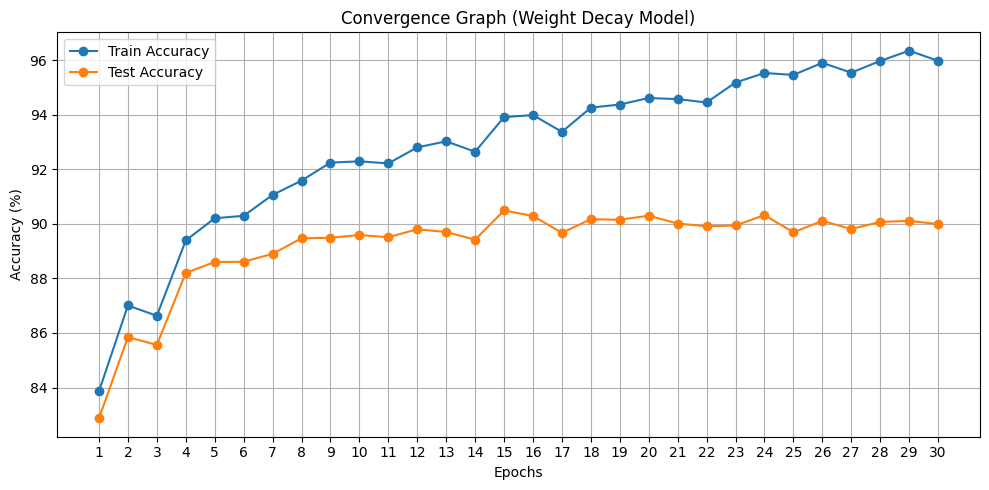

In [3]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

class LeNet5(nn.Module):
    def __init__(self):
        super(LeNet5, self).__init__()
        self.conv1 = nn.Conv2d(1, 6, kernel_size=5)
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.conv2 = nn.Conv2d(6, 16, kernel_size=5)
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.fc1 = nn.Linear(16 * 4 * 4, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        x = self.pool1(torch.relu(self.conv1(x)))
        x = self.pool2(torch.relu(self.conv2(x)))
        x = x.view(-1, 16 * 4 * 4)
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = self.fc3(x)
        return x

transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])
train_dataset = torchvision.datasets.FashionMNIST(root='./data', train=True, transform=transform, download=True)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_dataset = torchvision.datasets.FashionMNIST(root='./data', train=False, transform=transform, download=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

net = LeNet5()
criterion = nn.CrossEntropyLoss()


# weight_decay
optimizer = optim.Adam(net.parameters(), lr=0.001, weight_decay=1e-4)

epoch_losses = []
train_accuracies = []
test_accuracies = []
num_epochs = 30

for epoch in range(num_epochs):
    net.train()
    running_loss = 0.0
    for i, data in enumerate(train_loader, 0):
        inputs, labels = data
        optimizer.zero_grad()
        outputs = net(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()

    epoch_loss = running_loss / len(train_loader)
    epoch_losses.append(epoch_loss)

    net.eval()


    correct_train = 0
    total_train = 0
    with torch.no_grad():
        for data in train_loader:
            inputs, labels = data
            outputs = net(inputs)
            _, predicted = torch.max(outputs.data, 1)
            total_train += labels.size(0)
            correct_train += (predicted == labels).sum().item()
    train_accuracy = 100 * correct_train / total_train
    train_accuracies.append(train_accuracy)

    correct_test = 0
    total_test = 0
    with torch.no_grad():
        for data in test_loader:
            inputs, labels = data
            outputs = net(inputs)
            _, predicted = torch.max(outputs.data, 1)
            total_test += labels.size(0)
            correct_test += (predicted == labels).sum().item()
    test_accuracy = 100 * correct_test / total_test
    test_accuracies.append(test_accuracy)

    print(f"Epoch {epoch + 1}/{num_epochs}, Loss: {epoch_loss:.4f}, Train Accuracy: {train_accuracy:.2f}%, Test Accuracy: {test_accuracy:.2f}%")

print("Finished Training")
SAVE_PATH = "weight_decay_model.pth"
torch.save(net.state_dict(), SAVE_PATH)
print(f"Model weights saved to {SAVE_PATH}")


plt.figure(figsize=(10, 5))
plt.plot(range(1, num_epochs + 1), train_accuracies, marker='o', label='Train Accuracy')
plt.plot(range(1, num_epochs + 1), test_accuracies, marker='o', label='Test Accuracy')
plt.title('Convergence Graph (Weight Decay Model)')
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True)
plt.xticks(range(1, num_epochs + 1))
plt.tight_layout()
plt.savefig("weight_decay_convergence_graph.png")

print(f"\nFinal Train Accuracy: {train_accuracies[-1]:.2f}%")
print(f"Final Test Accuracy: {test_accuracies[-1]:.2f}%")
print("Convergence graph saved as 'weight_decay_convergence_graph.png'")

Epoch 1/30, Loss: 0.4641, Train Accuracy: 89.19%, Test Accuracy: 87.43%
Epoch 2/30, Loss: 0.3094, Train Accuracy: 90.44%, Test Accuracy: 88.21%
Epoch 3/30, Loss: 0.2775, Train Accuracy: 91.75%, Test Accuracy: 89.31%
Epoch 4/30, Loss: 0.2559, Train Accuracy: 91.91%, Test Accuracy: 89.18%
Epoch 5/30, Loss: 0.2354, Train Accuracy: 92.47%, Test Accuracy: 89.38%
Epoch 6/30, Loss: 0.2223, Train Accuracy: 92.93%, Test Accuracy: 89.43%
Epoch 7/30, Loss: 0.2087, Train Accuracy: 93.44%, Test Accuracy: 90.04%
Epoch 8/30, Loss: 0.1973, Train Accuracy: 93.46%, Test Accuracy: 89.33%
Epoch 9/30, Loss: 0.1884, Train Accuracy: 94.39%, Test Accuracy: 89.86%
Epoch 10/30, Loss: 0.1793, Train Accuracy: 94.93%, Test Accuracy: 90.06%
Epoch 11/30, Loss: 0.1705, Train Accuracy: 94.28%, Test Accuracy: 89.63%
Epoch 12/30, Loss: 0.1608, Train Accuracy: 95.34%, Test Accuracy: 90.37%
Epoch 13/30, Loss: 0.1545, Train Accuracy: 95.42%, Test Accuracy: 89.66%
Epoch 14/30, Loss: 0.1498, Train Accuracy: 95.65%, Test Accu

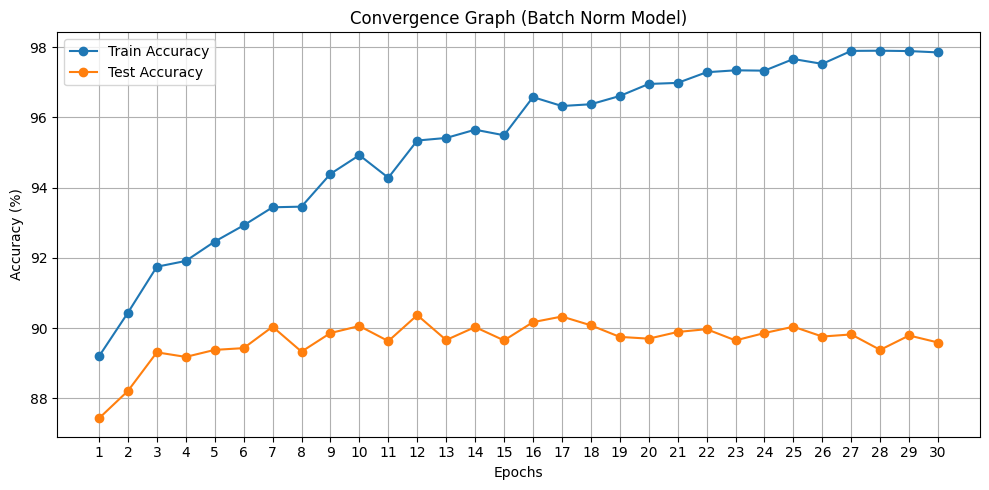

In [4]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

class LeNet5_BN(nn.Module):
    def __init__(self):
        super(LeNet5_BN, self).__init__()
        self.conv1 = nn.Conv2d(1, 6, kernel_size=5)
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.conv2 = nn.Conv2d(6, 16, kernel_size=5)
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)

        self.fc1 = nn.Linear(16 * 4 * 4, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)


        self.bn_conv1 = nn.BatchNorm2d(6)
        self.bn_conv2 = nn.BatchNorm2d(16)
        self.bn_fc1 = nn.BatchNorm1d(120)
        self.bn_fc2 = nn.BatchNorm1d(84)

    def forward(self, x):
        # Conv -> BN -> ReLU -> Pool
        x = self.pool1(torch.relu(self.bn_conv1(self.conv1(x))))
        x = self.pool2(torch.relu(self.bn_conv2(self.conv2(x))))

        x = x.view(-1, 16 * 4 * 4)

        # FC -> BN -> ReLU
        x = torch.relu(self.bn_fc1(self.fc1(x)))
        x = torch.relu(self.bn_fc2(self.fc2(x)))

        x = self.fc3(x)
        return x

transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])
train_dataset = torchvision.datasets.FashionMNIST(root='./data', train=True, transform=transform, download=True)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_dataset = torchvision.datasets.FashionMNIST(root='./data', train=False, transform=transform, download=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

net = LeNet5_BN()
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(net.parameters(), lr=0.001)

epoch_losses = []
train_accuracies = []
test_accuracies = []
num_epochs = 30

for epoch in range(num_epochs):
    net.train()
    running_loss = 0.0
    for i, data in enumerate(train_loader, 0):
        inputs, labels = data
        optimizer.zero_grad()
        outputs = net(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()

    epoch_loss = running_loss / len(train_loader)
    epoch_losses.append(epoch_loss)

    net.eval()

    correct_train = 0
    total_train = 0
    with torch.no_grad():
        for data in train_loader:
            inputs, labels = data
            outputs = net(inputs)
            _, predicted = torch.max(outputs.data, 1)
            total_train += labels.size(0)
            correct_train += (predicted == labels).sum().item()
    train_accuracy = 100 * correct_train / total_train
    train_accuracies.append(train_accuracy)

    correct_test = 0
    total_test = 0
    with torch.no_grad():
        for data in test_loader:
            inputs, labels = data
            outputs = net(inputs)
            _, predicted = torch.max(outputs.data, 1)
            total_test += labels.size(0)
            correct_test += (predicted == labels).sum().item()
    test_accuracy = 100 * correct_test / total_test
    test_accuracies.append(test_accuracy)

    print(f"Epoch {epoch + 1}/{num_epochs}, Loss: {epoch_loss:.4f}, Train Accuracy: {train_accuracy:.2f}%, Test Accuracy: {test_accuracy:.2f}%")

print("Finished Training")
SAVE_PATH = "batch_norm_model.pth"
torch.save(net.state_dict(), SAVE_PATH)
print(f"Model weights saved to {SAVE_PATH}")

plt.figure(figsize=(10, 5))
plt.plot(range(1, num_epochs + 1), train_accuracies, marker='o', label='Train Accuracy')
plt.plot(range(1, num_epochs + 1), test_accuracies, marker='o', label='Test Accuracy')
plt.title('Convergence Graph (Batch Norm Model)')
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True)
plt.xticks(range(1, num_epochs + 1))
plt.tight_layout()
plt.savefig("batch_norm_convergence_graph.png")

print(f"\nFinal Train Accuracy: {train_accuracies[-1]:.2f}%")
print(f"Final Test Accuracy: {test_accuracies[-1]:.2f}%")
print("Convergence graph saved as 'batch_norm_convergence_graph.png'")

In [8]:

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

data = {
    "Model": ["Baseline", "Dropout", "Weight Decay", "Batch Normalization"],
    "Final Train Accuracy (%)": [96.81, 91.75, 95.98, 97.85],
    "Final Test Accuracy (%)":  [90.04, 89.01, 89.99, 89.59],
}
df = pd.DataFrame(data)
display(df)


,Model,Final Train Accuracy (%),Final Test Accuracy (%)
0,Baseline,96.81,90.04
1,Dropout,91.75,89.01
2,Weight Decay,95.98,89.99
3,Batch Normalization,97.85,89.59
